# Hof Co-op: planet population analysis (add-planets)

Analysis of runs made with `run_model_Hof.py` and `config/popsynth/DiscConfig_Hof_add-planets.json` (planets with `Mp = "SI"` are inserted where planetesimals form, then grown and migrated with the Bitsch model).

Units: `t` in the HDF5 file is in **yr** (shown here in Myr); `Rp` in AU; `Mcs`, `Mes` in M⊕.

In [14]:
# ==== IMPORTS AND DIRECTORIES ====
# (Hof, 2026-11-11) Set-up cell for the planet-population ("add-planets") analysis.
# Runs come from run_model_Hof.py with config/popsynth/DiscConfig_Hof_add-planets.json.
import os
import re

import h5py
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Directory holding the add-planets pilot output (.h5). The run is written by
# run_model_Hof.py; per-planet series are HDF5 groups Mcs/<ip>, Mes/<ip>, Rp/<ip>
# with one row per entry of the dataset "t" [yr] (see run_model_Hof.py,
# create_planet_datasets() / write_planet_row()).
DATADIR_PILOT = "/home/imontesd/scratch/output/DiscEvolution/popsynth/add-planets/pilot_v1"

# Where figures are saved (None = do not save). Created on first save.
FIGDIR = None

### Planet evolution tracks (pilot v1)

Total mass (core + envelope, M⊕) against orbital radius (AU) for every planet in one pilot run. Same style as the *Planet evolution tracks* cell in `HJpaper.ipynb` (`compare_models_onepanel`):
- each line is one planet, coloured by its starting radius;
- the open circle is where the planet starts (its insertion point for `"SI"` planets);
- filled circles mark every 0.33 Myr, more opaque as time goes on.

This plot shows one model only. It uses a log colour scale from 0.2 to 30 AU (HJpaper used a linear 0–30 AU scale).

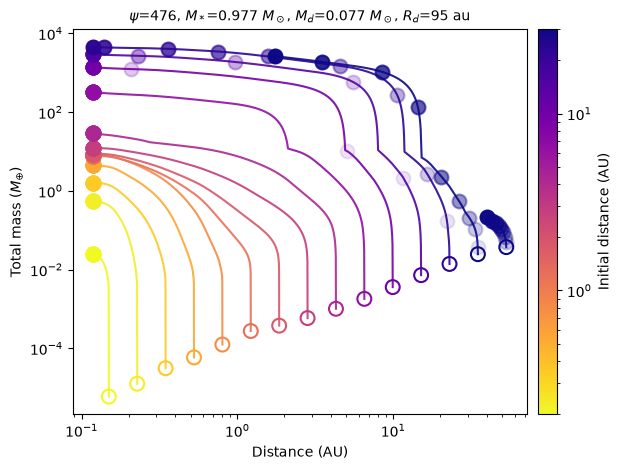

t_end = 3.000 Myr, complete = True, N planets = 15
 ip  cfg R_ins[AU] t_form[Myr] R_fin[AU]    Mc[ME]    Me[ME]  Mtot[ME]
  0    1     0.150       0.000     0.119    0.0241  0.000563    0.0247
  1    2     0.228       0.000     0.119     0.538   0.00171      0.54
  2    3     0.346       0.000     0.119      1.61     0.012      1.63
  3    4     0.526       0.000     0.119      4.35    0.0809      4.43
  4    5     0.801       0.000     0.119      7.84     0.268      8.11
  5    6     1.218       0.001     0.119      7.54     0.265      7.81
  6    7     1.853       0.001     0.119      8.45     0.356       8.8
  7    8     2.819       0.003     0.119      11.5     0.751      12.3
  8    9     4.288       0.006     0.119      8.54      20.2      28.8
  9   10     6.524       0.012     0.119      5.91       317       323
 10   11     9.924       0.025     0.119      5.39  1.39e+03  1.39e+03
 11   12    15.096       0.053     0.119      5.42  2.98e+03  2.98e+03
 12   13    22.964       0

In [15]:
# ==== PLANET EVOLUTION TRACKS (single run) ====
# (Hof, 2026-11-11) Total-mass growth tracks M_core + M_env [Mearth] vs orbital
# radius R_p [AU] for every planet in ONE run_model_Hof.py output file.
# Modelled on compare_models_onepanel() in HJpaper.ipynb ("Planet evolution tracks"
# cell, the paper's Fig. 6), with the same conventions:
#   * one line per planet, coloured by its starting radius ("Initial distance (AU)"
#     colour bar, cmap "plasma_r");
#   * circle markers every TIME_MARKER_INTERVAL_MYR [Myr], whose fill opacity grows
#     with time (alpha = t_mark / t_max), so you can read how fast each planet moved;
#   * the starting point is an OPEN circle.
# Differences from HJpaper (needed for this run):
#   1. One model per panel (HJpaper overlays two models, solid vs dashed).
#   2. Planets with Mp = "SI" are inserted only when planetesimals form at their
#      radius (streaming instability), so they may appear AFTER t = 0. run_model_Hof.py
#      backfills their rows with NaN until then (see _make_backfilled()). Here:
#        - the start point / colour comes from the Rp/<ip> attribute R_insert_au [AU]
#          (HJpaper uses Rp[ip][0], which would be NaN for a late insertion);
#        - the open circle sits at the INSERTION point (= t = 0 for planets present
#          from the start), and time markers are drawn only after insertion.
#   3. Colour scale is LOGARITHMIC between 0.2 and 30 AU (the planets.Rp range in
#      DiscConfig_Hof_add-planets.json). HJpaper used a linear 0-30 AU scale; with
#      8 of 16 radii inside 3 AU a linear scale would make those lines look alike.
#   4. A planet that the code stops writing early (e.g. removed at the inner edge)
#      has a shorter series than "t"; time is truncated to its length.
# Units: t [yr] in the file -> Myr here (/1e6); Rp [AU]; Mcs, Mes [Mearth].

PILOT_FILE = os.path.join(
    DATADIR_PILOT,
    "hof_add-planets_pilotv1_gamma1_psi476.0_erad0.967521_Ms0.977_aSS1.0e-05"
    "_Mdot7.4e-08_M7.7e-02_Rd9.5e+01.h5",
)

TIME_MARKER_INTERVAL_MYR = 0.33   # Myr between time markers (same as HJpaper)
R_COLOR_LIM_AU = (0.2, 30.0)      # AU, colour-bar range (log scale), see note 3


def load_planet_tracks_Hof(fname):
    """
    Read the per-planet time series of one run_model_Hof.py output file.

    Returns a dict:
        t_yr    : (nt,) time of each planet row [yr]  (dataset "t")
        planets : list (HDF5 index order = insertion order) of dicts with
                  ip            HDF5 index (str key of the Rp group)
                  config_index  position in config planets.Rp / planets.Mp (-1 if absent)
                  R_insert_au   insertion radius [AU]
                  t_form_Myr    insertion time [Myr]
                  Rp_au         (n,) orbital radius [AU]   (NaN before insertion)
                  Mc_Mearth     (n,) core mass [Mearth]
                  Me_Mearth     (n,) envelope mass [Mearth]
        params  : run parameters parsed from the filename (psi, erad, Ms [Msun],
                  aSS, Mdot [Msun/yr], M [Msun], Rd [AU]); missing tokens -> NaN
        complete: h5 attribute "complete" (False if the run did not finish)
    """
    out = {"planets": [], "params": {}}
    base = os.path.basename(fname)
    # Filename tokens written by run_model_Hof.py::output_filename()
    for key, pat in [("psi", r"_psi([0-9.eE+-]+?)_"), ("erad", r"_erad([0-9.eE+-]+?)_"),
                     ("Ms", r"_Ms([0-9.eE+-]+?)_"), ("aSS", r"_aSS([0-9.eE+-]+?)_Mdot"),
                     ("Mdot", r"_Mdot([0-9.eE+-]+?)_M"), ("M", r"_M([0-9.eE+-]+?)_Rd"),
                     ("Rd", r"_Rd([0-9.eE+-]+?)\.h5$")]:
        m = re.search(pat, base)
        out["params"][key] = float(m.group(1)) if m else np.nan

    with h5py.File(fname, "r") as f:
        out["t_yr"] = np.asarray(f["t"][()], dtype=float)                 # yr
        out["complete"] = bool(f.attrs.get("complete", False))
        if "Rp" not in f or len(f["Rp"].keys()) == 0:
            print(f"No planets in {base} (include_planets off, or none inserted yet).")
            return out
        for ip in sorted(f["Rp"].keys(), key=int):
            Rp = np.asarray(f["Rp"][ip][()], dtype=float)                 # AU
            Mc = np.asarray(f["Mcs"][ip][()], dtype=float)                # Mearth
            Me = np.asarray(f["Mes"][ip][()], dtype=float)                # Mearth
            a = f["Rp"][ip].attrs
            finite = np.isfinite(Rp)
            # Fallbacks for files written before the attributes existed:
            # first finite radius / time of the first finite row.
            R_ins = float(a["R_insert_au"]) if "R_insert_au" in a else (
                Rp[finite][0] if finite.any() else np.nan)
            t_ins_yr = float(a["t_form_yr"]) if "t_form_yr" in a else (
                out["t_yr"][np.argmax(finite)] if finite.any() else np.nan)
            out["planets"].append({
                "ip": ip,
                "config_index": int(a.get("config_index", -1)),
                "R_insert_au": R_ins,
                "t_form_Myr": t_ins_yr / 1e6,                              # yr -> Myr
                "Rp_au": Rp, "Mc_Mearth": Mc, "Me_Mearth": Me,
            })
    return out


def plot_planet_tracks_Hof(fname, planets=None, cmap="plasma_r",
                           time_marker_interval=TIME_MARKER_INTERVAL_MYR,
                           r_color_lim=R_COLOR_LIM_AU, xlim=None, ylim=None,
                           figdir=None):
    """
    Plot total mass (M_core + M_env) [Mearth] vs R_p [AU] for each planet of one run.
        planets : iterable of HDF5 planet indices (int) to draw; None = all
        figdir  : directory to save a PNG into (None = do not save)
    Returns (fig, ax, data) where data is the load_planet_tracks_Hof() dict.
    """
    data = load_planet_tracks_Hof(fname)
    if not data["planets"]:
        return None, None, data
    t_all_Myr = data["t_yr"] / 1e6                                         # yr -> Myr
    t_max = np.nanmax(t_all_Myr)                                           # Myr, end of run
    sel = [p for p in data["planets"] if planets is None or int(p["ip"]) in planets]

    norm = mpl.colors.LogNorm(vmin=r_color_lim[0], vmax=r_color_lim[1])   # AU
    cmap_obj = plt.get_cmap(cmap)

    fig, ax = plt.subplots()
    for p in sel:
        c = cmap_obj(norm(p["R_insert_au"]))
        n = len(p["Rp_au"])
        t_Myr = t_all_Myr[:n]                                              # note 4
        x = p["Rp_au"]                                                     # AU
        y = p["Mc_Mearth"] + p["Me_Mearth"]                                # Mearth
        ok = np.isfinite(x) & np.isfinite(y) & (y > 0)                     # drop NaN backfill
        if not ok.any():
            continue
        ax.loglog(x[ok], y[ok], color=c, linestyle="-", alpha=0.9)

        # Open circle at the insertion point (HJpaper: open circle at t = 0)
        i0 = np.argmax(ok)
        ax.scatter(x[i0], y[i0], facecolors="none", edgecolors=c, s=100,
                   marker="o", linewidths=1.5, zorder=5)

        # Filled markers every time_marker_interval [Myr] after insertion, with fill
        # opacity = t_mark / t_max (HJpaper's "progressive filling")
        for t_mark in np.arange(time_marker_interval, t_max, time_marker_interval):
            if t_mark < t_Myr[i0] or t_mark > t_Myr[ok][-1]:
                continue                       # planet not yet inserted / no longer written
            idx = np.argmin(np.abs(t_Myr - t_mark))
            if not ok[idx]:
                continue
            ax.scatter(x[idx], y[idx], color=c, edgecolors=c, s=100, marker="o",
                       alpha=t_mark / t_max, linewidths=1.5, zorder=5)

    ax.set_xlabel("Distance (AU)")
    ax.set_ylabel("Total mass ($M_⊕$)")
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)

    # Short run label: wind strength psi (dimensionless), M* [Msun], initial disc
    # mass M [Msun] and characteristic radius Rd [AU], from the filename
    pr = data["params"]
    ax.set_title(rf"$\psi$={pr['psi']:g}, $M_*$={pr['Ms']:g} $M_\odot$, "
                 rf"$M_d$={pr['M']:.2g} $M_\odot$, $R_d$={pr['Rd']:g} au"
                 + ("" if data["complete"] else "  [run incomplete]"), fontsize=10)

    sm = mpl.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Initial distance (AU)")
    plt.tight_layout()

    if figdir:
        os.makedirs(figdir, exist_ok=True)
        outname = os.path.join(figdir, os.path.basename(fname).replace(".h5", "_tracks_Mtot_vs_R.png"))
        fig.savefig(outname, dpi=200)
        print(f"Saved {outname}")
    return fig, ax, data


fig, ax, tracks_pilot = plot_planet_tracks_Hof(PILOT_FILE, figdir=FIGDIR)
plt.show()

# Summary table: one line per planet (HDF5 insertion order)
print(f"t_end = {tracks_pilot['t_yr'][-1] / 1e6:.3f} Myr, complete = {tracks_pilot['complete']}, "
      f"N planets = {len(tracks_pilot['planets'])}")
print(f"{'ip':>3} {'cfg':>4} {'R_ins[AU]':>9} {'t_form[Myr]':>11} {'R_fin[AU]':>9} "
      f"{'Mc[ME]':>9} {'Me[ME]':>9} {'Mtot[ME]':>9}")
for p in tracks_pilot["planets"]:
    last = np.flatnonzero(np.isfinite(p["Rp_au"]))
    j = last[-1] if last.size else -1
    print(f"{p['ip']:>3} {p['config_index']:>4} {p['R_insert_au']:9.3f} {p['t_form_Myr']:11.3f} "
          f"{p['Rp_au'][j]:9.3f} {p['Mc_Mearth'][j]:9.3g} {p['Me_Mearth'][j]:9.3g} "
          f"{p['Mc_Mearth'][j] + p['Me_Mearth'][j]:9.3g}")

### Planet total mass vs time (pilot v1)

Total mass (core + envelope, M⊕) against time (Myr) for the same planets as the tracks plot above, with the same colour coding (starting radius, log scale 0.2–30 AU).
- An open circle marks insertion: t = 0, or the insertion time for `"SI"` planets.
- A filled circle marks the last saved point.

The time axis is linear by default; call with `logt=True` for a log axis, which shows the early growth more clearly. This cell reuses `tracks_pilot` from the cell above, so run that cell first.

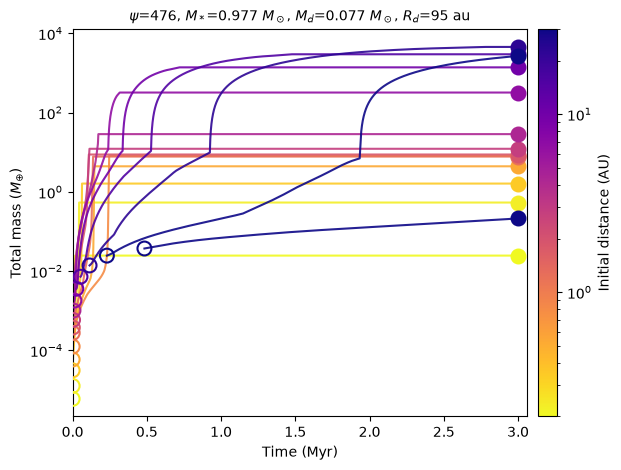

In [16]:
# ==== PLANET TOTAL MASS vs TIME (single run) ====
# (Hof, 2026-11-11) Companion to the tracks cell above: total mass
# M_core + M_env [Mearth] against time t [Myr] for every planet of the same run.
# HJpaper.ipynb has no mass-vs-time panel, so this keeps the conventions of the
# tracks cell (and of HJpaper's compare_models_onepanel) instead:
#   * one line per planet, coloured by insertion radius R_insert_au [AU], with the
#     same log colour scale (R_COLOR_LIM_AU) and "Initial distance (AU)" colour bar;
#   * OPEN circle at the insertion point (t_form; t = 0 for planets present at start);
#   * FILLED circle at the last written row (final mass, or the moment the code
#     stopped writing the planet).
# The 0.33 Myr time markers of the tracks plot are dropped here: with time on the
# x-axis they would only repeat the axis ticks.
# Time axis: LINEAR by default (0 to t_end), so the insertion times of "SI" planets
# are easy to read. Set logt=True for a log time axis (resolves the fast early
# growth); rows with t = 0 are then dropped, since log(0) is undefined.
# Uses tracks_pilot (the load_planet_tracks_Hof() dict from the cell above), so the
# file is not read twice. Units: t [yr] in the file -> Myr (/1e6); masses in Mearth.


def plot_planet_mass_vs_time_Hof(data, planets=None, cmap="plasma_r",
                                 r_color_lim=R_COLOR_LIM_AU, logt=False,
                                 xlim=None, ylim=None, figdir=None, fname=None):
    """
    Plot total mass (M_core + M_env) [Mearth] vs time [Myr] for each planet of one run.
        data    : dict from load_planet_tracks_Hof()
        planets : iterable of HDF5 planet indices (int) to draw; None = all
        logt    : False = linear time axis (default), True = log time axis
        figdir  : directory to save a PNG into (None = do not save); needs fname
                  (the .h5 path) to build the PNG name
    Returns (fig, ax).
    """
    if not data["planets"]:
        print("No planets to plot.")
        return None, None
    t_all_Myr = data["t_yr"] / 1e6                                         # yr -> Myr
    sel = [p for p in data["planets"] if planets is None or int(p["ip"]) in planets]

    norm = mpl.colors.LogNorm(vmin=r_color_lim[0], vmax=r_color_lim[1])   # AU
    cmap_obj = plt.get_cmap(cmap)

    fig, ax = plt.subplots()
    plotfunc = ax.loglog if logt else ax.semilogy
    for p in sel:
        c = cmap_obj(norm(p["R_insert_au"]))
        n = len(p["Mc_Mearth"])
        t_Myr = t_all_Myr[:n]                      # truncate to this planet's rows (Myr)
        y = p["Mc_Mearth"] + p["Me_Mearth"]        # Mearth
        ok = np.isfinite(y) & (y > 0)              # drop NaN backfill before insertion
        if logt:
            ok &= t_Myr > 0                        # log axis cannot show t = 0
        if not ok.any():
            continue
        plotfunc(t_Myr[ok], y[ok], color=c, linestyle="-", alpha=0.9)
        i0, i1 = np.flatnonzero(ok)[[0, -1]]       # first / last plotted row
        ax.scatter(t_Myr[i0], y[i0], facecolors="none", edgecolors=c, s=100,
                   marker="o", linewidths=1.5, zorder=5)     # insertion
        ax.scatter(t_Myr[i1], y[i1], color=c, edgecolors=c, s=100,
                   marker="o", linewidths=1.5, zorder=5)     # last written row

    ax.set_xlabel("Time (Myr)")
    ax.set_ylabel("Total mass ($M_⊕$)")
    if xlim:
        ax.set_xlim(xlim)
    elif not logt:
        # Myr, start of run to t_end, plus a 2% margin so the final-mass circles
        # at t_end are not cut in half by the axis edge
        ax.set_xlim(0, 1.02 * np.nanmax(t_all_Myr))
    if ylim: ax.set_ylim(ylim)

    # Same run label as the tracks plot (psi dimensionless, M* and M_d in Msun, R_d in au)
    pr = data["params"]
    ax.set_title(rf"$\psi$={pr['psi']:g}, $M_*$={pr['Ms']:g} $M_\odot$, "
                 rf"$M_d$={pr['M']:.2g} $M_\odot$, $R_d$={pr['Rd']:g} au"
                 + ("" if data["complete"] else "  [run incomplete]"), fontsize=10)

    sm = mpl.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Initial distance (AU)")
    plt.tight_layout()

    if figdir and fname:
        os.makedirs(figdir, exist_ok=True)
        tag = "_Mtot_vs_logt.png" if logt else "_Mtot_vs_t.png"
        outname = os.path.join(figdir, os.path.basename(fname).replace(".h5", tag))
        fig.savefig(outname, dpi=200)
        print(f"Saved {outname}")
    return fig, ax


fig, ax = plot_planet_mass_vs_time_Hof(tracks_pilot, figdir=FIGDIR, fname=PILOT_FILE)
plt.show()

### Movie: planet mass vs radius over time (pilot v1)

Each frame is one moment in time. Every planet that exists at that moment is drawn as a circle at its radius (AU) and total mass (M⊕), with a faded line showing its path so far. Colours are the starting radius, as in the plots above.
- The dashed line marks one Jupiter mass, M_J = 317.8 M⊕ (`Mjup / Mearth` in `DiscEvolution/constants.py`).
- The top-left corner shows the time and how many planets are at or above M_J.

There are 100 frames, evenly spaced from 0 to the end of the run. Each frame uses the latest planet data at or before its time.

**For slides:** the cell saves an animated GIF and shows that GIF as its output. Right-click it to copy it into a slideshow.
- The GIF is 640×480 px at 10 frames/s. It loops forever and holds the last frame for 2 s.
- It is saved to `MOVIE_DIR` (`FIGDIR` if set, otherwise `./movies_Hof`). If pasting gives a still image, insert that file instead.
- `SHOW_JS_PLAYER = True` brings back the inline play/scrub player.

This cell reuses `tracks_pilot`, so run the tracks cell first.

Saved /project/6000781/imontesd/DiscEvolution/example/StartHere/notebooks/movies_Hof/hof_add-planets_pilotv1_gamma1_psi476.0_erad0.967521_Ms0.977_aSS1.0e-05_Mdot7.4e-08_M7.7e-02_Rd9.5e+01_movie_Mtot_vs_R.gif  (1.19 MB)


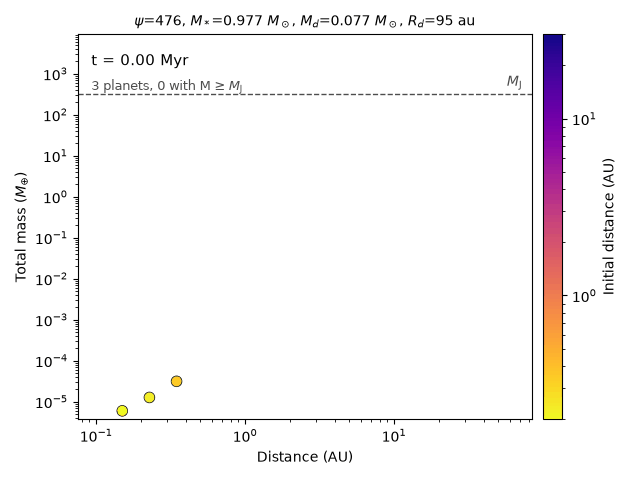

In [17]:
# ==== MOVIE: PLANET MASS vs RADIUS, ONE FRAME PER TIME SNAPSHOT ====
# (Hof, 2026-11-11) Animated version of the tracks plot: each frame shows every
# planet that exists at time t as a circle at (R_p [AU], M_core + M_env [Mearth]),
# with a faded line behind it showing its path up to t.
#   * Colours: insertion radius R_insert_au [AU], same log scale (R_COLOR_LIM_AU),
#     cmap and colour bar as the two static plots above.
#   * Dashed horizontal line: Jupiter mass, M_J = Mjup / Mearth = 317.8 Mearth
#     (DiscEvolution/constants.py), to see which planets become gas giants.
#   * Frames: N_FRAMES_MOVIE times evenly spaced from 0 to t_end [Myr]. Planet rows
#     are written every 5 time steps (thousands of rows), far too many to show one
#     per frame, so each frame uses the last planet row at or before its time
#     (np.searchsorted on "t"). The disc snapshots in time_snap (34 of them in
#     DiscConfig_Hof_add-planets.json) would be too few for smooth motion.
#   * A planet appears only once it is inserted ("SI" planets: NaN rows before
#     t_form), and disappears if the code stops writing it.
# Output (Hof, 2026-11-11, changed for slides): the movie is ALWAYS written as an
# animated GIF with Pillow (no ffmpeg needed; ffmpeg is not installed on this WSL
# machine), then shown in the cell output AS THAT GIF (mime type image/gif), so it
# can be right-clicked / copied straight from the notebook into a slideshow.
#   * The GIF loops forever (matplotlib's PillowWriter writes loop=0), which is what
#     slide software expects for an embedded animation.
#   * The last frame is held for MOVIE_HOLD_END_S [s] before the loop restarts, so
#     the final state can be read during a talk.
#   * Saved to MOVIE_DIR (FIGDIR if set, else ./movies_Hof next to this notebook) as
#     <h5 name>_movie_Mtot_vs_R.gif. If pasting from the notebook gives a still
#     image (some clipboards keep only the first frame), insert that file instead.
#   * The old inline JavaScript player (FuncAnimation.to_jshtml, play/scrub buttons)
#     is still available with SHOW_JS_PLAYER = True; it cannot be copied as a GIF
#     and adds a few MB of PNG frames to the notebook, so it is off by default.
# Uses tracks_pilot from the tracks cell (run it first). Units: t [yr] -> Myr (/1e6).
from matplotlib import animation
from IPython.display import HTML, Image, display
from DiscEvolution.constants import Mjup, Mearth      # both in g

M_JUP_MEARTH = Mjup / Mearth      # Mearth, Jupiter mass (= 317.8)
N_FRAMES_MOVIE = 100              # number of frames (time snapshots)
MOVIE_FPS = 10                    # frames per second in the GIF
MOVIE_DPI = 100                   # dots per inch: default 6.4 x 4.8 in figure -> 640 x 480 px GIF
MOVIE_HOLD_END_S = 2.0            # s, how long the last frame stays on screen before looping
SHOW_TRAILS = True                # draw each planet's path up to the current time
SHOW_JS_PLAYER = False            # True = also show the inline play/scrub player (not copyable as GIF)
# Folder for the GIF (always written now, since the cell output displays that file)
MOVIE_DIR = FIGDIR if FIGDIR else os.path.join(os.getcwd(), "movies_Hof")

# Allow the (optional) inline player to exceed matplotlib's default 20 MB embed limit (in MB)
mpl.rcParams["animation.embed_limit"] = 100


def make_planet_movie_Hof(data, n_frames=N_FRAMES_MOVIE, fps=MOVIE_FPS, dpi=MOVIE_DPI,
                          cmap="plasma_r", r_color_lim=R_COLOR_LIM_AU,
                          show_trails=SHOW_TRAILS, hold_end_s=MOVIE_HOLD_END_S,
                          xlim=None, ylim=None, movie_dir=MOVIE_DIR, fname=None):
    """
    Build a FuncAnimation of planet total mass [Mearth] vs radius [AU] over time.
        data   : dict from load_planet_tracks_Hof()
        xlim, ylim : axis limits; None = from the data (all planets, all times),
                     with ylim widened to always include the Jupiter-mass line
        hold_end_s : s, extra time the last frame is shown before the GIF loops
        movie_dir  : directory the GIF is written to (created if needed)
        fname      : the .h5 path, used to name the GIF
    Returns (anim, gif_path): the FuncAnimation and the path of the saved GIF.
    """
    t_all_Myr = data["t_yr"] / 1e6                                       # yr -> Myr
    P = data["planets"]
    if not P:
        print("No planets to animate.")
        return None, None

    # Per planet: radius [AU] and total mass [Mearth], padded with NaN to the
    # length of "t" so every planet can be indexed with the same row number
    nt = len(t_all_Myr)
    R_arr = np.full((len(P), nt), np.nan)
    M_arr = np.full((len(P), nt), np.nan)
    for k, p in enumerate(P):
        n = len(p["Rp_au"])
        R_arr[k, :n] = p["Rp_au"]
        M_arr[k, :n] = p["Mc_Mearth"] + p["Me_Mearth"]
    good = np.isfinite(R_arr) & np.isfinite(M_arr) & (M_arr > 0)

    # Axis limits from all finite points (0.2 dex padding in log space)
    if xlim is None:
        xlim = (R_arr[good].min() / 10**0.2, R_arr[good].max() * 10**0.2)          # AU
    if ylim is None:
        ylim = (M_arr[good].min() / 10**0.2,
                max(M_arr[good].max(), M_JUP_MEARTH) * 10**0.3)                     # Mearth

    norm = mpl.colors.LogNorm(vmin=r_color_lim[0], vmax=r_color_lim[1])  # AU
    cmap_obj = plt.get_cmap(cmap)
    colors = [cmap_obj(norm(p["R_insert_au"])) for p in P]

    fig, ax = plt.subplots(dpi=dpi)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("Distance (AU)")
    ax.set_ylabel("Total mass ($M_⊕$)")

    # Jupiter mass reference line (Mearth), labelled at the right edge
    ax.axhline(M_JUP_MEARTH, color="0.3", linestyle="--", linewidth=1, zorder=1)
    ax.text(0.98, M_JUP_MEARTH * 1.15, r"$M_\mathrm{J}$", transform=ax.get_yaxis_transform(),
            ha="right", va="bottom", color="0.3", fontsize=10)

    pr = data["params"]
    ax.set_title(rf"$\psi$={pr['psi']:g}, $M_*$={pr['Ms']:g} $M_\odot$, "
                 rf"$M_d$={pr['M']:.2g} $M_\odot$, $R_d$={pr['Rd']:g} au"
                 + ("" if data["complete"] else "  [run incomplete]"), fontsize=10)
    sm = mpl.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Initial distance (AU)")

    # Artists updated each frame: one trail line per planet, one scatter for the
    # current positions, and the time stamp
    trails = [ax.plot([], [], color=c, alpha=0.4, linewidth=1)[0] for c in colors] if show_trails else []
    dots = ax.scatter([], [], s=60, edgecolors="k", linewidths=0.5, zorder=5)
    t_text = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top", fontsize=11)
    n_text = ax.text(0.03, 0.88, "", transform=ax.transAxes, va="top", fontsize=9, color="0.3")
    plt.tight_layout()

    # Frame times [Myr] and, for each, the last planet row with t <= frame time
    frame_t_Myr = np.linspace(0.0, np.nanmax(t_all_Myr), n_frames)
    frame_row = np.clip(np.searchsorted(t_all_Myr, frame_t_Myr, side="right") - 1, 0, nt - 1)

    # Hold the last frame: n_hold extra frames that all redraw the final time, i.e.
    # hold_end_s [s] at fps frames/s. (Pillow merges identical consecutive frames into
    # one longer frame, so this adds almost nothing to the GIF size.)
    n_hold = int(round(hold_end_s * fps))

    def update(i):
        i = min(i, n_frames - 1)                 # frames >= n_frames repeat the last one
        j = frame_row[i]
        alive = good[:, j]                       # planets that exist at this row
        if alive.any():
            dots.set_offsets(np.column_stack([R_arr[alive, j], M_arr[alive, j]]))
            dots.set_facecolors([colors[k] for k in np.flatnonzero(alive)])
        else:
            dots.set_offsets(np.empty((0, 2)))
        for k, ln in enumerate(trails):
            m = good[k, :j + 1]
            ln.set_data(R_arr[k, :j + 1][m], M_arr[k, :j + 1][m])
        n_giant = int(np.sum(M_arr[alive, j] >= M_JUP_MEARTH))
        t_text.set_text(f"t = {t_all_Myr[j]:.2f} Myr")
        n_text.set_text(f"{alive.sum()} planets, {n_giant} with M ≥ $M_\\mathrm{{J}}$")
        return [dots, t_text, n_text, *trails]

    anim = animation.FuncAnimation(fig, update, frames=n_frames + n_hold,
                                   interval=1000 / fps, blit=False)

    # Always write the GIF (looping forever, loop=0 in PillowWriter)
    os.makedirs(movie_dir, exist_ok=True)
    base = os.path.basename(fname) if fname else "planet_movie.h5"
    gif_path = os.path.join(movie_dir, base.replace(".h5", "_movie_Mtot_vs_R.gif"))
    anim.save(gif_path, writer=animation.PillowWriter(fps=fps), dpi=dpi)
    print(f"Saved {gif_path}  ({os.path.getsize(gif_path) / 1e6:.2f} MB)")
    plt.close(fig)               # stop the notebook also showing the last frame as a static figure
    return anim, gif_path


anim_pilot, gif_pilot = make_planet_movie_Hof(tracks_pilot, fname=PILOT_FILE)
if gif_pilot is not None:
    # Show the saved GIF itself (mime type image/gif): right-click the output to
    # copy it into a slideshow. Reading the bytes (not linking the path) keeps the
    # image in the notebook even if the file is moved.
    with open(gif_pilot, "rb") as fh:
        display(Image(data=fh.read(), format="gif"))
    if SHOW_JS_PLAYER:
        display(HTML(anim_pilot.to_jshtml()))

## Planet seeding distribution

Embryo seeds are spaced evenly in log **orbital period**: 20 periods from 1 day to 100 yr (`P_distr`). They are converted to semi-major axes for each star with Kepler's third law, $a = (G M_\star P^2/4\pi^2)^{1/3}$, which in code units ($G$ = AU = M$_\odot$ = 1, `yr` = $2\pi$) is $a\,[\mathrm{AU}] = (M_\star/M_\odot)^{1/3}(P/\mathrm{yr})^{2/3}$.

- **Stars:** the 500 discs of the v5 population (`malanga_mstar_draws_Hof_N500_seed1_xirmin.csv`).
- **`a_distr`:** array of shape (N_star, 20), in AU. `seeds_df` is the same as a long table, with flags for seeds inside the disc grid $[r_{\rm min}, r_{\rm max}]$ and within $5R_0$ (`N_R0_SEED`; about 99% of the initial disc mass).
- **Figure:** one row per disc, ordered by increasing disc ID from the top (drawn by `plot_seed_rows_Hof`, reused below for subsets). Disc ID is on the left and $M_\star$ on the right; $a$ (AU, log scale) is on both the top and bottom axes.
  - **Grey dots:** the 20 seeds. Filled if inside the grid, open if outside (lost).
  - **◀ / ▶:** $r_{\rm min}$ / $r_{\rm max}$.
  - **Green:** $5R_0$.
  - **Faint dashed line:** along each row, to make comparisons within a disc easier.
  - **Coloured segment, from $r_{\rm min}$ to $r_{\rm max}$ only:** the disc's total surface density at $t=0$, $\log_{10}(\Sigma_{\rm tot}/\Sigma_{\rm max})$. Each disc is normalised to its own maximum, so colours compare positions within a disc, not between discs. The colour bar runs from −6 dex (pale) to 0 (dark). It is computed analytically from the code's initial profile $\Sigma \propto (R/R_0)^{-1}e^{-R/R_0}$ (`disc_setup_Hof.py`, γ = 1); the uniform dust-to-gas ratio cancels on normalising.
  - **Size:** the figure is about 100 in tall (`ROW_HEIGHT_SEED_IN` = 0.2 in per row). With `FIGDIR` set it is also saved as a zoomable PDF.

[2.73972603e-03 4.26098826e-03 6.62694765e-03 1.03066313e-02
 1.60294988e-02 2.49300498e-02 3.87727271e-02 6.03016994e-02
 9.37848641e-02 1.45859915e-01 2.26850195e-01 3.52811197e-01
 5.48713395e-01 8.53392387e-01 1.32724765e+00 2.06421614e+00
 3.21039427e+00 4.99300008e+00 7.76541688e+00 1.20772478e+01
 1.87832691e+01 2.92128805e+01 4.54336454e+01 7.06611639e+01
 1.09896532e+02 1.70917759e+02 2.65821677e+02 4.13422011e+02
 6.42979013e+02 1.00000000e+03]
Read 500 stars from /project/6000781/imontesd/DiscEvolution/example/StartHere/notebooks/../config/malanga/malanga_mstar_draws_Hof_N500_seed1_xirmin.csv

Seed radii span 0.00909 - 108 AU over all stars (M_star = 0.1 - 1.27 Msun)
Seeds per disc inside the grid [r_min, r_max]: min 16, median 24, max 26 (of 30)
Seeds per disc inside the grid AND within 5 R0: min 11, median 21, max 26 (of 30)
Seeds inside r_min (lost): median 5 per disc | outside r_max: 198 discs have >= 1 | discs with 5 R0 beyond the outermost seed: 135

pilot_v1 star (0.9



(<Figure size 800x10280 with 3 Axes>,
 <Axes: xlabel='Semi-major axis $a$ (AU)', ylabel='Disc ID (increasing, top to bottom)'>)

In [ ]:
import numpy as np
import pandas as pd
# (Hof, 2026-11-11) The original line "from constants import G" failed (ModuleNotFoundError): constants.py lives inside
# the DiscEvolution package, so it must be imported as DiscEvolution.constants (as the movie cell does for Mjup).
# G = 1 and yr = 2*pi there (code units: G = AU = Msun = 1, time unit = yr / 2pi).
from DiscEvolution.constants import G, yr

# Embryo orbital periods [yr] (user's choice).
P_distr = np.geomspace(1/(365), 1000, 30)

print(P_distr)

# According to Kepler's Law, assuming M_star >> M_embryo, P^2 = 4*pi^2/G * a^3 / M_star
# For every star, we calculate the corresponding seeding location distribution (a_distr)
#
# (Hof, 2026-11-11) Completed below. Solving Kepler's law for the semi-major axis:
#     a = (G * M_star * P^2 / (4 pi^2))^(1/3)
# in CODE units: M_star [Msun], a [AU], and P in code time = P[yr] * yr (yr = 2 pi code units per year). With G = 1 this is
#     a[AU] = (M_star/Msun)^(1/3) * (P/yr)^(2/3)
# (check: P = 1 yr around 1 Msun -> a = 1 AU). Each period P_k therefore sits at a different radius around each star, scaling
# as M_star^(1/3): a factor 10 in M_star moves every seed out by 10^(1/3) = 2.15.
#
# "Every star" = the 500 discs of the v5 population (the per-disc draws file read by the popsynth launcher), which also
# gives each disc's grid edges r_min, r_max [AU] and initial characteristic radius R0 [AU]. A seed outside [r_min, r_max]
# would be outside the simulated disc (disc.interp returns the edge value there), so the cell counts them per disc.
# R0: with the gamma = 1 initial profile, M(<R) ~ 1 - exp(-R/R0), so 3 R0 encloses ~95% and 5 R0 ~99% of the initial disc
# mass. (Hof, 2026-11-11, revised) the outer reference is now N_R0_SEED * R0 with N_R0_SEED = 5 (was 3), for the flags,
# printout and figure alike.
N_R0_SEED = 5                      # dimensionless: outer reference radius = N_R0_SEED * R0 [AU] (5 R0 ~ 99% of initial mass)
_frac_R0 = 1 - np.exp(-N_R0_SEED)  # fraction of the initial disc mass inside N_R0_SEED * R0 (gamma = 1)

SEED_DRAWS_FILE = "malanga_mstar_draws_Hof_N500_seed1_xirmin.csv"     # v5 population (xi calibrated on r_min)
_candidates = [os.path.join(os.getcwd(), "..", "config", "malanga", SEED_DRAWS_FILE),           # notebook run from notebooks/
               os.path.join("/home/imontesd/DiscEvolution/example/StartHere/config/malanga", SEED_DRAWS_FILE)]
SEED_DRAWS_PATH = next((p for p in _candidates if os.path.exists(p)), _candidates[-1])
stars_seed = pd.read_csv(SEED_DRAWS_PATH)                                # one row per disc / star
print(f"Read {len(stars_seed)} stars from {SEED_DRAWS_PATH}")

M_star = stars_seed["Mstar_Msun"].to_numpy()                             # Msun, (N_star,)
P_code = P_distr * yr                                                    # yr -> code time units, (N_P,)

# a_distr[i, k] = semi-major axis [AU] of period P_distr[k] around star i; shape (N_star, N_P)
a_distr = (G * M_star[:, None] * P_code[None, :] ** 2 / (4 * np.pi ** 2)) ** (1 / 3)
assert np.isclose((G * 1.0 * (1.0 * yr) ** 2 / (4 * np.pi ** 2)) ** (1 / 3), 1.0)   # 1 yr around 1 Msun = 1 AU

# Long table (one row per star and period) for later use, e.g. to build each disc's planets.Rp list
seeds_df = pd.DataFrame({
    "id": np.repeat(stars_seed["id"].to_numpy(), len(P_distr)),
    "Mstar_Msun": np.repeat(M_star, len(P_distr)),                       # Msun
    "P_yr": np.tile(P_distr, len(M_star)),                               # yr
    "a_au": a_distr.ravel(),                                             # AU
    "rmin_au": np.repeat(stars_seed["rmin_au"].to_numpy(), len(P_distr)),
    "rmax_au": np.repeat(stars_seed["rmax_au"].to_numpy(), len(P_distr)),
    "R0_au": np.repeat(stars_seed["R0_au"].to_numpy(), len(P_distr)),
})
seeds_df["on_grid"] = (seeds_df.a_au >= seeds_df.rmin_au) & (seeds_df.a_au <= seeds_df.rmax_au)
COL_IN_R0_SEED = f"in_{N_R0_SEED}R0"                                     # column name, e.g. "in_5R0"
seeds_df[COL_IN_R0_SEED] = seeds_df.on_grid & (seeds_df.a_au <= N_R0_SEED * seeds_df.R0_au)

# ---- summary ----
print(f"\nSeed radii span {a_distr.min():.3g} - {a_distr.max():.3g} AU over all stars "
      f"(M_star = {M_star.min():.3g} - {M_star.max():.3g} Msun)")
for name, col in [("inside the grid [r_min, r_max]", "on_grid"), (f"inside the grid AND within {N_R0_SEED} R0", COL_IN_R0_SEED)]:
    n = seeds_df.groupby("id")[col].sum()
    print(f"Seeds per disc {name}: min {n.min()}, median {n.median():.0f}, max {n.max()} (of {len(P_distr)})")
_below = (seeds_df.a_au < seeds_df.rmin_au).groupby(seeds_df.id).sum()
_above = (seeds_df.a_au > seeds_df.rmax_au).groupby(seeds_df.id).sum()
print(f"Seeds inside r_min (lost): median {_below.median():.0f} per disc | outside r_max: {int((_above > 0).sum())} discs "
      f"have >= 1 | discs with {N_R0_SEED} R0 beyond the outermost seed: "
      f"{int((N_R0_SEED * stars_seed.R0_au > a_distr[:, -1]).sum())}")

# Example: the pilot_v1 star (M_star = 0.977017 Msun, r_min = 0.09832 AU in config/add-planets/DiscConfig_Hof_add-planets-baseline.json)
_a_pilot = (G * 0.977017 * P_code ** 2 / (4 * np.pi ** 2)) ** (1 / 3)
print("\npilot_v1 star (0.977 Msun): a [AU] =", np.array2string(_a_pilot, precision=3, separator=", "))


# ---- figure: one row per disc (Hof, 2026-11-11, revised; replaces the a vs M_star plot) ----
# x = seed semi-major axis a [AU] (log). y = one row per disc, ordered by INCREASING DISC ID from the top (Hof, 2026-11-12;
# was increasing stellar mass), labelled on the left with the disc ID (CSV column "id") and on the right with M_star [Msun].
# The figure is drawn by plot_seed_rows_Hof() below, which the next cell reuses for subsets of discs.
# On each row:
#   * grey dots      = the 20 seeds a_distr[i, :]; filled if inside the disc grid [r_min, r_max], open if outside
#                      (an open seed would be outside the simulated disc);
#   * left triangle  "<" = r_min [AU], inner grid edge;   right triangle ">" = r_max [AU], outer grid edge;
#   * green dot      = N_R0_SEED * R0 [AU] (5 R0 ~ 99% of the initial disc mass);
#   * faint dashed line along the row, so the markers of one disc are easy to compare;
#   * (Hof, 2026-11-11) COLOURED segment from r_min to r_max (i.e. only between the blue and red triangles): the disc's
#     TOTAL surface density at t = 0, normalised to ITS OWN maximum (see below), so colours compare positions WITHIN a
#     disc, never magnitudes between discs.
# Total surface density at t = 0. The code starts every disc with (disc_setup_Hof.py, line 555)
#     Sigma_G(R) = Sigma_c (R/R0)^-gamma exp[-(R/R0)^(2-gamma)]      [g/cm^2], gamma = 1 for v5,
# and dust = d2g * Sigma_G with a UNIFORM d2g (0.01; no planetesimals yet), so Sigma_total = (1 + d2g) Sigma_G has the same
# shape. Dividing by the disc's own maximum removes Sigma_c, M0 and d2g:
#     Sigma / Sigma_max = (R/r_min)^-1 exp[-(R - r_min)/R0]           (gamma = 1: Sigma falls monotonically, so max at r_min)
# so no HDF5 output is needed (the v5 runs are on Nibi). Colour = log10(Sigma / Sigma_max), clipped to
# [-SIGMA_DYN_RANGE_DEX, 0]: a LOG scale, because Sigma drops by many orders of magnitude between r_min and r_max
# (R^-1 alone gives 2-3 dex inside R0; at 5 R0 it is typically 1e-5 - 1e-6 of the maximum).
# Rows are ROW_HEIGHT_SEED_IN inches apart, so the figure is very tall (500 x 0.2 in ~ 100 in): scroll through it, or set
# FIGDIR to also save a PDF, which can be zoomed without losing resolution. The x axis is labelled at top and bottom.
ROW_HEIGHT_SEED_IN = 0.2            # inches between neighbouring disc rows (larger = more space per disc)
SEED_LABEL_FS = 6                   # pt, font size of the disc-ID / M_star row labels
SIGMA_DYN_RANGE_DEX = 6.0           # dex: colour scale spans log10(Sigma/Sigma_max) from -6 (palest) to 0 (darkest)
SIGMA_CMAP_SEED = "magma"           # pale yellow (high Sigma) -> near-black (low Sigma); PERCEPTUALLY UNIFORM, so equal steps
                                    # in log Sigma look like equal colour steps ("YlOrBr" packed most change into -1..-2 dex)
N_SIGMA_PTS_SEED = 200              # points per disc (log-spaced in R from r_min to r_max) for the coloured segment
SIGMA_LW_SEED = 3.5                 # pt, width of the coloured segment
MIN_AXES_H_SEED_IN = 1.5            # inches, minimum height of the plotting area (for subsets with few discs)
from matplotlib.collections import LineCollection


def plot_seed_rows_Hof(idx, title_extra="", fname="seed_distribution_per_disc.pdf", keep_order=False,
                       ylabel="Disc ID (increasing, top to bottom)"):
    """
    (Hof, 2026-11-12) The one-row-per-disc seed figure, as a function so the same plot can be drawn for any subset of
    discs (next cell). Before, this code ran inline for all 500 discs only, sorted by M_star.
        idx         : positional indices into stars_seed / a_distr of the discs to draw (any order, any length)
        title_extra : text appended to the figure title (e.g. which subset this is)
        fname       : PDF file name, saved into FIGDIR if FIGDIR is set
        keep_order  : (Hof, 2026-11-12) False (default) = rows sorted by disc ID; True = rows in the ORDER OF idx as passed
                      (first index at the top), e.g. pre-sorted by disc mass in the subset cell
        ylabel      : (Hof, 2026-11-12) left y-axis label; say how the rows are ordered when keep_order=True
    Rows are ORDERED BY DISC ID (CSV column "id"), increasing from the top (changed 2026-11-12; was increasing M_star),
    unless keep_order=True.
    Disc ID on the left, M_star [Msun] on the right. Height = ROW_HEIGHT_SEED_IN per row + fixed margins [in].
    Returns (fig, ax).
    """
    idx = np.asarray(idx, dtype=int)
    if keep_order:
        _order = idx                                                     # caller's order (first = top row)
    else:
        _order = idx[np.argsort(stars_seed["id"].to_numpy()[idx], kind="stable")]   # star indices sorted by increasing ID
    _rows = np.arange(len(_order))                                       # row number of each sorted star (0 = top)
    _st = stars_seed.iloc[_order].reset_index(drop=True)                 # stars in plotting order
    _a = a_distr[_order]                                                 # AU, (N_rows, N_P) in plotting order
    _ongrid = (_a >= _st.rmin_au.to_numpy()[:, None]) & (_a <= _st.rmax_au.to_numpy()[:, None])
    _yy = np.repeat(_rows[:, None], _a.shape[1], axis=1)                 # row of every seed

    # Margins are fixed in INCHES (not fractions), so the title / legend / top axis keep the same size whatever the height
    _top_in, _bot_in = 2.1, 0.7                                          # inches above / below the axes (top: room for colour bar)
    # axes height [in]: ROW_HEIGHT_SEED_IN per row, but at least MIN_AXES_H_SEED_IN so a small subset (e.g. 2 discs) still
    # has room for the y-axis labels (rows are then simply spaced further apart)
    _fig_h = max(len(_rows) * ROW_HEIGHT_SEED_IN, MIN_AXES_H_SEED_IN) + _top_in + _bot_in   # inches
    fig, ax = plt.subplots(figsize=(8.0, _fig_h))
    fig.subplots_adjust(top=1 - _top_in / _fig_h, bottom=_bot_in / _fig_h, left=0.09, right=0.88)
    # faint dashed guide line along every row (x in axes fraction 0-1, y in data = row number)
    ax.hlines(_rows, 0, 1, transform=ax.get_yaxis_transform(), colors="0.5", linestyles="--", linewidth=0.5,
              alpha=0.3, zorder=0)
    # (Hof, 2026-11-11) coloured Sigma(t = 0) segment of every disc, r_min -> r_max only, as ONE LineCollection.
    # For disc i: N_SIGMA_PTS_SEED radii log-spaced in [r_min, r_max] [AU]; each little segment between neighbouring radii is
    # coloured by log10(Sigma/Sigma_max) at its geometric-mean radius.
    _rmin_s, _rmax_s, _R0_s = (_st[c].to_numpy() for c in ("rmin_au", "rmax_au", "R0_au"))      # AU, plotting order
    _Rs = np.geomspace(_rmin_s, _rmax_s, N_SIGMA_PTS_SEED, axis=1)       # AU, (N_rows, N_SIGMA_PTS_SEED)
    _Rmid = np.sqrt(_Rs[:, :-1] * _Rs[:, 1:])                            # AU, segment mid-points (log)
    _logS = (np.log10(_rmin_s[:, None] / _Rmid)                          # log10(Sigma/Sigma_max) = -log10(R/r_min)
             - (_Rmid - _rmin_s[:, None]) / _R0_s[:, None] / np.log(10)) #   - (R - r_min)/R0 / ln 10
    _yseg = np.repeat(_rows[:, None], N_SIGMA_PTS_SEED - 1, axis=1)      # row of every segment
    _segs = np.stack([np.stack([_Rs[:, :-1], _yseg], -1),
                      np.stack([_Rs[:, 1:], _yseg], -1)], axis=2)        # (N_rows, n-1, 2 ends, (x, y))
    _sig_norm = mpl.colors.Normalize(vmin=-SIGMA_DYN_RANGE_DEX, vmax=0.0)   # dex
    _lc = LineCollection(_segs.reshape(-1, 2, 2), cmap=SIGMA_CMAP_SEED, norm=_sig_norm, linewidths=SIGMA_LW_SEED,
                         capstyle="projecting", zorder=1)
    # capstyle "projecting": each segment extends half a line width past its ends, so neighbouring segments overlap and no
    # white antialiasing seams show between them ("butt" left visible stripes). The extra ~1.75 pt at r_min / r_max is
    # hidden under the triangles.
    _lc.set_array(np.clip(_logS.ravel(), -SIGMA_DYN_RANGE_DEX, 0.0))     # below -SIGMA_DYN_RANGE_DEX -> end colour
    ax.add_collection(_lc)
    # seeds drawn ON the coloured segment: white edge so the dark-grey dots stay visible on the dark (low-Sigma) end
    ax.scatter(_a[_ongrid], _yy[_ongrid], s=12, color="0.25", edgecolors="white", linewidths=0.4, zorder=2,
               label="seed, inside the grid")
    ax.scatter(_a[~_ongrid], _yy[~_ongrid], s=10, facecolors="none", edgecolors="0.35", linewidths=0.6, zorder=2,
               label="seed, outside the grid (lost)")
    # (white edges: keep the triangles visible on any colour of the segment)
    ax.scatter(_st.rmin_au, _rows, s=26, marker="<", color="C0", edgecolors="white", linewidths=0.5, zorder=3,
               label=r"$r_{\rm min}$ (inner grid edge)")
    ax.scatter(_st.rmax_au, _rows, s=26, marker=">", color="C3", edgecolors="white", linewidths=0.5, zorder=3,
               label=r"$r_{\rm max}$ (outer grid edge)")
    ax.scatter(N_R0_SEED * _st.R0_au, _rows, s=14, color="C2", zorder=3,
               label=rf"${N_R0_SEED}R_0$ (~{100 * _frac_R0:.0f}% of initial disc mass)")
    ax.set_xscale("log")
    ax.set_ylim(len(_rows) - 0.5, -0.5)                                  # inverted: row 0 (lowest ID / first of idx) at the top
    ax.margins(y=0)
    ax.set_yticks(_rows)
    ax.set_yticklabels([str(int(i)) for i in _st["id"]], fontsize=SEED_LABEL_FS)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Semi-major axis $a$ (AU)")
    # the same log x axis repeated at the TOP of the long plot (secondary axis = identity copy of the bottom one)
    ax.secondary_xaxis("top").set_xlabel("Semi-major axis $a$ (AU)")
    ax.grid(True, axis="x", which="major", color="0.85", lw=0.6, zorder=0)
    # right-hand labels: M_star [Msun] of each row
    ax_r = ax.twinx()
    ax_r.set_ylim(ax.get_ylim())
    ax_r.set_yticks(_rows)
    ax_r.set_yticklabels([f"{m:.3f}" for m in _st.Mstar_Msun], fontsize=SEED_LABEL_FS)
    ax_r.set_ylabel(r"$M_\star$ ($M_\odot$)")
    # title and legend in the top margin, positioned in inches from the top edge (0.15 in and 0.45 in)
    fig.suptitle(f"Embryo seeds: {len(P_distr)} periods, {P_distr[0] * 365:.0f} d to {P_distr[-1]:.0f} yr, "
                 f"{len(_rows)} discs{title_extra}", fontsize=10, y=1 - 0.15 / _fig_h, va="top")
    _h, _l = ax.get_legend_handles_labels()
    fig.legend(_h, _l, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 1 - 0.45 / _fig_h), ncols=3, frameon=False)
    # horizontal colour bar for the Sigma segments, in the top margin: 0.95-1.05 in below the top edge, 40% of the width
    _cax = fig.add_axes([0.30, 1 - 1.05 / _fig_h, 0.40, 0.10 / _fig_h])
    _cb = fig.colorbar(mpl.cm.ScalarMappable(norm=_sig_norm, cmap=SIGMA_CMAP_SEED), cax=_cax, orientation="horizontal",
                       extend="min")                                     # "min" arrow: values below -6 dex are clipped
    _cb.set_label(r"$\log_{10}(\Sigma_{\rm tot}/\Sigma_{\rm max})$ at $t=0$, normalised per disc (from $r_{\rm min}$ to $r_{\rm max}$)",
                  fontsize=7)
    _cb.ax.tick_params(labelsize=6)
    if FIGDIR:
        os.makedirs(FIGDIR, exist_ok=True)
        _out = os.path.join(FIGDIR, fname)
        fig.savefig(_out)
        print(f"Saved {_out}")
    plt.show()
    return fig, ax


# All 500 discs, ordered by ID
plot_seed_rows_Hof(np.arange(len(stars_seed)))

### Seed distribution: subsets of discs

The same figure (`plot_seed_rows_Hof`, rows ordered by disc ID) for two subsets of the v5 discs. Run the cell above first.
1. **Every disc with $\log_{10}(5R_0) - \log_{10}a_{\rm max} \geq 1$** (`LOG_GAP_MIN_SEED`), where $a_{\rm max}$ is the outermost seed inside the grid $[r_{\rm min}, r_{\rm max}]$. These are discs where $5R_0$ lies at least 10× beyond the last seed, so their outer disc gets no embryos over at least a factor of 10 in radius. Discs with $5R_0 < a_{\rm max}$ have a negative difference and are excluded. The table and the plot are both sorted by decreasing total initial disc mass, $(1+d_{\rm 2g})M_0$ (same order as $M_0$).
2. **Every disc with $5R_0 > r_{\rm max}$** (green dot outside the grid), i.e. more than about 1% of the initial disc mass lies beyond the outer grid edge.

**Mass beyond the last seed** *(2026-11-12)*. For both subsets the cell prints the initial disc mass between the outermost seed in the grid ($a_{\rm max}$) and $r_{\rm max}$, where no embryo is seeded, found by integrating the total surface density:
$$M(a_{\rm max}\to r_{\rm max}) = \int_{a_{\rm max}}^{r_{\rm max}} 2\pi R\,\Sigma_{\rm tot}(R)\,dR,\qquad \Sigma_{\rm tot} = (1+d_{\rm 2g})\,\Sigma_c\,(R/R_0)^{-1}e^{-R/R_0}.$$
- **$\Sigma_c$** is set so that the gas mass on the grid is $M_0$, as in `disc_setup_Hof.py`.
- **$d_{\rm 2g}$** is 0.01.
- **Method:** numerical trapezoid integration in `mass_between_Hof`.
- **Output:** the mass in M$_\odot$ (`M_amax_rmax_Msun`) and the fraction of the on-grid total (`f_M_amax_rmax`). A printed check compares the fraction with the closed form $[e^{-a_{\rm max}/R_0}-e^{-r_{\rm max}/R_0}]/[e^{-r_{\rm min}/R_0}-e^{-r_{\rm max}/R_0}]$.
- **For context:** `f_M_offgrid` $= e^{-r_{\rm max}/R_0}$ is the share of the untruncated profile beyond $r_{\rm max}$. That mass is rescaled onto the grid, so it is already included.

check: integrated Sigma_total vs closed form, max |difference in f| over all 500 discs = 5.8e-07
(1) 5 of 500 discs have log10(5 R0) - log10(a_max) >= 1 (5 R0 at least 10x beyond the outermost seed inside the grid); sorted by decreasing total disc mass (1 + d2g) M0:
 id  Mstar_Msun  R0_au  rmax_au  a_max_au  5R0_au  log_5R0_over_amax  M0_Msun  Sigma_tot_amax_gcm2  M_amax_rmax_Msun  f_M_amax_rmax  f_M_offgrid
247       0.687  238.3     1000     88.24    1192               1.13  0.01038               0.4946          0.007192          0.686      0.01505
445      0.2351  139.6     1000     61.72     698              1.053 0.009411                1.004          0.006108         0.6426    0.0007745
307      0.3038  139.4     1000     67.22     697              1.016 0.007393               0.6967           0.00461         0.6174    0.0007666
177      0.7312  199.4     1000     90.09     997              1.044 0.003552               0.1811          0.002276         0.6343     0.006637
 68     

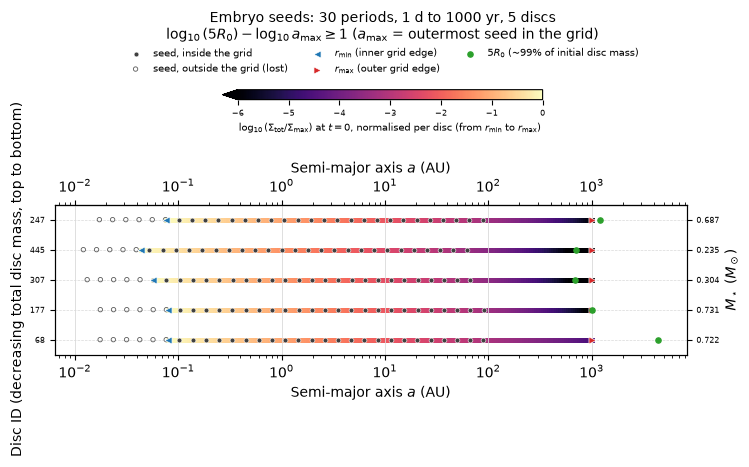


(2) 2 of 500 discs have 5 R0 > r_max (green dot outside the grid). 5 R0 / r_max: median 2.78, max 4.37
 id  Mstar_Msun  R0_au  rmax_au  a_max_au  5R0_au  M0_Msun  Sigma_tot_amax_gcm2  M_amax_rmax_Msun  f_M_amax_rmax  f_M_offgrid
 68      0.7221    874     1000     89.71    4370 0.003019              0.07285          0.002613          0.857       0.3185
247       0.687  238.3     1000     88.24    1192  0.01038               0.4946          0.007192          0.686      0.01505
(2): fraction of the simulated initial disc mass between the last seed in the grid (a_max) and r_max: median 0.772, mean 0.772, min 0.686, max 0.857; 2 of 2 discs above 10%, 2 above 50%
(2): that mass (integrated Sigma_total, gas + dust): median 0.0049 Msun, min 0.00261, max 0.00719 Msun (= 1.63e+03 Mearth median)
(2): (context) fraction of the untruncated profile beyond r_max, already rescaled onto the grid: median 0.17, max 0.32


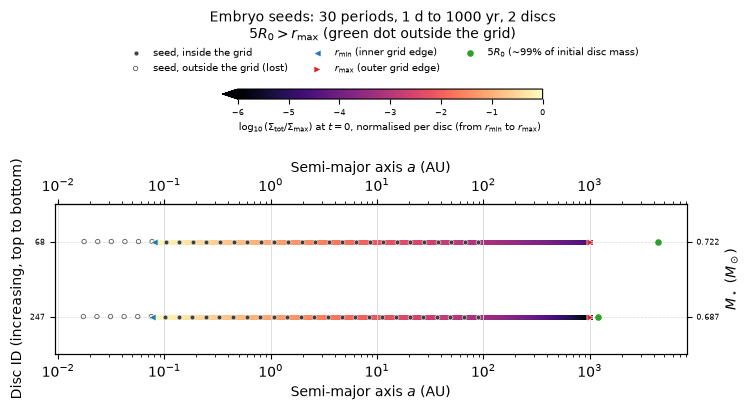

In [22]:
# ==== SEED DISTRIBUTION: SUBSETS OF DISCS ====
# (Hof, 2026-11-12) Same one-row-per-disc figure as the cell above (plot_seed_rows_Hof: rows ordered by disc ID, same
# markers, same per-disc normalised Sigma(t = 0) colouring), for two subsets of the 500 v5 discs. Run the cell above first
# (it defines stars_seed, a_distr, N_R0_SEED and plot_seed_rows_Hof).
#   (1) (Hof, 2026-11-12, revised; was the 30 discs with the largest |5 R0 - r_max| [AU]) every disc whose 5 R0 lies at
#       least LOG_GAP_MIN_SEED = 1 dex (a factor 10) beyond its OUTERMOST SEED INSIDE THE GRID, a_max:
#           log10(5 R0) - log10(a_max) >= 1,   a_max = max{ a_distr[i, k] : r_min <= a_distr[i, k] <= r_max }  [AU]
#       i.e. discs whose outer disc (out to 5 R0, ~99% of the initial mass) is left without embryos over a factor >= 10
#       in radius. Discs with 5 R0 < a_max have a NEGATIVE difference and so are excluded automatically by ">= 1".
#   (2) Every disc whose 5 R0 lies OUTSIDE the grid, i.e. 5 R0 > r_max: the disc's initial mass extends past the outer
#       grid edge (more than ~1% of it beyond r_max, since 5 R0 encloses ~99%).
LOG_GAP_MIN_SEED = 1.0                  # dex, subset (1): minimum log10(5 R0) - log10(a_max)


from DiscEvolution.constants import AU, Msun, Mearth                     # cm, g, g
D2G_SEED = 0.01                         # dimensionless, initial dust-to-gas ratio (disc.d2g in DiscConfig_Hof_malanga_mstar.json)
N_QUAD_SEED = 4000                      # quadrature points per integral (log-spaced in R)


def sigma_total_t0_Hof(R_au, rmin, rmax, R0, M0):
    """
    (Hof, 2026-11-12) TOTAL (gas + dust) surface density at t = 0, Sigma_total(R) [g/cm^2], as the code builds it:
        Sigma_G(R) = Sigma_c (R/R0)^-1 exp(-R/R0)                       (gamma = 1, disc_setup_Hof.py line 555)
        Sigma_c    : chosen so that the GAS mass ON THE GRID is M0      (disc_setup_Hof.py: Sigma *= Mdisk / Mtot())
        Sigma_total = (1 + d2g) Sigma_G                                  (dust = d2g * Sigma_G, uniform d2g = D2G_SEED)
    Sigma_c [g/cm^2] = M0 [g] / int_{rmin}^{rmax} 2 pi R (R/R0)^-1 exp(-R/R0) dR [cm^2], integrated numerically
    (np.trapezoid, N_QUAD_SEED log-spaced points).
        R_au : (N, Q) radii [AU];  rmin, rmax, R0 : (N,) [AU];  M0 : (N,) gas disc mass [Msun]
    """
    Rg = np.geomspace(rmin, rmax, N_QUAD_SEED, axis=1) * AU               # cm, (N, Q) normalisation grid
    shape_g = (Rg / (R0[:, None] * AU)) ** -1 * np.exp(-Rg / (R0[:, None] * AU))   # dimensionless
    Sigma_c = M0 * Msun / np.trapezoid(2 * np.pi * Rg * shape_g, Rg, axis=1)       # g/cm^2, (N,)
    shape = (R_au / R0[:, None]) ** -1 * np.exp(-R_au / R0[:, None])               # dimensionless
    return (1 + D2G_SEED) * Sigma_c[:, None] * shape                              # g/cm^2


def mass_between_Hof(r1, r2, rmin, rmax, R0, M0):
    """
    (Hof, 2026-11-12, revised) Initial disc mass between r1 and r2 [AU] from the INTEGRATED total surface density:
        M(r1 -> r2) = int_{r1}^{r2} 2 pi R Sigma_total(R) dR                  [g -> Msun]
    with Sigma_total from sigma_total_t0_Hof (numerical, np.trapezoid, N_QUAD_SEED log-spaced points from r1 to r2).
    Before (2026-11-12) this used the closed form [exp(-r1/R0) - exp(-r2/R0)] / [exp(-rmin/R0) - exp(-rmax/R0)]; the two
    agree to < 1e-6 (checked when the cell runs, see the "check" print).
    Returns (M_between [Msun], f = M_between / M_total_on_grid [dimensionless]), where the total (gas + dust) on-grid mass
    is int_{rmin}^{rmax} 2 pi R Sigma_total dR = (1 + d2g) M0. r1, r2 are clipped to [rmin, rmax]; all arrays (N,).
    """
    r1, r2 = np.clip(r1, rmin, rmax), np.clip(r2, rmin, rmax)
    Rq_au = np.geomspace(r1, r2, N_QUAD_SEED, axis=1)                     # AU, (N, Q) integration radii
    Sig = sigma_total_t0_Hof(Rq_au, rmin, rmax, R0, M0)                   # g/cm^2
    M_between = np.trapezoid(2 * np.pi * (Rq_au * AU) * Sig, Rq_au * AU, axis=1) / Msun   # Msun
    Rt_au = np.geomspace(rmin, rmax, N_QUAD_SEED, axis=1)                 # AU, whole grid
    M_total = np.trapezoid(2 * np.pi * (Rt_au * AU) * sigma_total_t0_Hof(Rt_au, rmin, rmax, R0, M0),
                           Rt_au * AU, axis=1) / Msun                     # Msun, = (1 + d2g) M0
    return M_between, M_between / M_total


_5R0 = N_R0_SEED * stars_seed["R0_au"].to_numpy()                       # AU, 5 R0 of every disc
_dgap = _5R0 - stars_seed["rmax_au"].to_numpy()                         # AU, signed: > 0 -> 5 R0 beyond r_max

# ---- (1) log10(5 R0) - log10(a_max) >= LOG_GAP_MIN_SEED ----
# a_max [AU] = outermost seed inside [r_min, r_max] of each disc (NaN if a disc had no seed in the grid; none does in v5)
_on = (a_distr >= stars_seed["rmin_au"].to_numpy()[:, None]) & (a_distr <= stars_seed["rmax_au"].to_numpy()[:, None])
# off-grid seeds set to -inf (NOT NaN: np.max returns NaN for any row containing a NaN, and every disc has off-grid seeds)
a_max_seed = np.where(_on, a_distr, -np.inf).max(axis=1)               # AU, (N_star,)
a_max_seed[~np.isfinite(a_max_seed)] = np.nan                           # no seed in the grid -> NaN (excluded below)
_log_gap = np.log10(_5R0) - np.log10(a_max_seed)                        # dex; < 0 when 5 R0 lies inside a_max
# (Hof, 2026-11-12) mass between the last seed in the grid and the outer grid edge, for every disc:
#   M_amax_rmax = initial (gas + dust) disc mass in [a_max, r_max] [Msun] = integral of 2 pi R Sigma_total(R) dR
#                 (mass_between_Hof; no embryo is seeded there);
#   f_amax_rmax = M_amax_rmax / total on-grid disc mass, i.e. the fraction of the SIMULATED initial disc mass;
#   f_offgrid   = fraction of the UNTRUNCATED analytic profile beyond r_max = exp(-r_max/R0) (draws CSV column
#                 f_mass_offgrid, sample_malanga_mstar_Hof.offgrid_mass_fraction). This mass is not lost: the code
#                 rescales Sigma onto the grid, so it is already counted inside f_amax_rmax. Printed for context only.
_rmin_all, _rmax_all = stars_seed["rmin_au"].to_numpy(), stars_seed["rmax_au"].to_numpy()        # AU
_R0_all, _M0_all = stars_seed["R0_au"].to_numpy(), stars_seed["M0_Msun"].to_numpy()               # AU, Msun
_amax_q = np.where(np.isfinite(a_max_seed), a_max_seed, _rmax_all)     # AU; a disc with no seed in the grid -> 0 mass
M_amax_rmax, f_amax_rmax = mass_between_Hof(_amax_q, _rmax_all, _rmin_all, _rmax_all, _R0_all, _M0_all)   # Msun, -
# (Hof, 2026-11-12) total (gas + dust) surface density AT the last seed in the grid, Sigma_tot(a_max) [g/cm^2]: the same
# profile that is integrated above (sigma_total_t0_Hof: gas mass on the grid = M0, times 1 + d2g), evaluated at R = a_max.
# (_amax_q[:, None]: one radius per disc as an (N, 1) array; [:, 0] back to (N,).) NaN-free: a disc with no seed in the
# grid would use r_max here, but none exists in v5.
Sigma_tot_amax = sigma_total_t0_Hof(_amax_q[:, None], _rmin_all, _rmax_all, _R0_all, _M0_all)[:, 0]   # g/cm^2
_f_closed = ((np.exp(-_amax_q / _R0_all) - np.exp(-_rmax_all / _R0_all))
             / (np.exp(-_rmin_all / _R0_all) - np.exp(-_rmax_all / _R0_all)))   # old closed form, for the check only
print(f"check: integrated Sigma_total vs closed form, max |difference in f| over all {len(f_amax_rmax)} discs = "
      f"{np.max(np.abs(f_amax_rmax - _f_closed)):.1e}")
f_offgrid_seed = stars_seed["f_mass_offgrid"].to_numpy()               # dimensionless


def print_mass_frac_Hof(idx, label):
    '''(Hof, 2026-11-12) Summary of f_amax_rmax (and f_offgrid) over the discs idx (positional indices).'''
    if len(idx) == 0:
        return
    f = f_amax_rmax[idx]
    print(f"{label}: fraction of the simulated initial disc mass between the last seed in the grid (a_max) and r_max: "
          f"median {np.median(f):.3f}, mean {np.mean(f):.3f}, min {np.min(f):.3f}, max {np.max(f):.3f}; "
          f"{int((f > 0.1).sum())} of {len(f)} discs above 10%, {int((f > 0.5).sum())} above 50%")
    print(f"{label}: that mass (integrated Sigma_total, gas + dust): median {np.median(M_amax_rmax[idx]):.3g} Msun, "
          f"min {np.min(M_amax_rmax[idx]):.3g}, max {np.max(M_amax_rmax[idx]):.3g} Msun "
          f"(= {np.median(M_amax_rmax[idx]) * Msun / Mearth:.3g} Mearth median)")
    print(f"{label}: (context) fraction of the untruncated profile beyond r_max, already rescaled onto the grid: "
          f"median {np.median(f_offgrid_seed[idx]):.2g}, max {np.max(f_offgrid_seed[idx]):.2g}")
idx_gap = np.flatnonzero(_log_gap >= LOG_GAP_MIN_SEED)                  # positional indices (NaN compares False)
# (Hof, 2026-11-12) order subset (1) by DECREASING TOTAL initial disc mass, M_tot = (1 + d2g) M0 [Msun] (gas + dust; the
# uniform d2g does not change the order, so this is also decreasing M0). Table AND plot use this order (most massive first).
M_tot0_seed = (1 + D2G_SEED) * _M0_all                                  # Msun, total initial disc mass of every disc
idx_gap = idx_gap[np.argsort(-M_tot0_seed[idx_gap], kind="stable")]
_tab = stars_seed.iloc[idx_gap][["id", "Mstar_Msun", "R0_au", "rmax_au"]].copy()
_tab["a_max_au"] = a_max_seed[idx_gap]
_tab["5R0_au"] = _5R0[idx_gap]
_tab["log_5R0_over_amax"] = _log_gap[idx_gap]
_tab["M0_Msun"] = _M0_all[idx_gap]                               # Msun, initial GAS disc mass M0 (draws CSV; (Hof, 2026-11-12) added)
_tab["Sigma_tot_amax_gcm2"] = Sigma_tot_amax[idx_gap]               # g/cm^2, Sigma_tot(t = 0) at R = a_max ((Hof, 2026-11-12) added)
_tab["M_amax_rmax_Msun"] = M_amax_rmax[idx_gap]                  # Msun, integrated Sigma_total in [a_max, r_max]
_tab["f_M_amax_rmax"] = f_amax_rmax[idx_gap]                            # simulated-mass fraction in [a_max, r_max]
_tab["f_M_offgrid"] = f_offgrid_seed[idx_gap]                           # untruncated-profile fraction beyond r_max
# (no re-sort: rows already in idx_gap order = decreasing total disc mass; was sorted by largest gap, 2026-11-12)
print(f"(1) {len(idx_gap)} of {len(stars_seed)} discs have log10({N_R0_SEED} R0) - log10(a_max) >= {LOG_GAP_MIN_SEED:g} "
      f"({N_R0_SEED} R0 at least {10 ** LOG_GAP_MIN_SEED:g}x beyond the outermost seed inside the grid); "
      f"sorted by decreasing total disc mass (1 + d2g) M0:")
print(_tab.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print_mass_frac_Hof(idx_gap, "(1)")
if len(idx_gap):
    plot_seed_rows_Hof(idx_gap, title_extra=f"\n$\\log_{{10}}({N_R0_SEED}R_0) - \\log_{{10}}a_{{\\rm max}} \\geq {LOG_GAP_MIN_SEED:g}$ "
                                            f"($a_{{\\rm max}}$ = outermost seed in the grid)",
                       fname=f"seed_distribution_log5R0_amax_ge{LOG_GAP_MIN_SEED:g}.pdf",
                       keep_order=True, ylabel="Disc ID (decreasing total disc mass, top to bottom)")

# ---- (2) 5 R0 outside the grid (5 R0 > r_max) ----
idx_out = np.flatnonzero(_dgap > 0)                                     # positional indices
print(f"\n(2) {len(idx_out)} of {len(stars_seed)} discs have {N_R0_SEED} R0 > r_max (green dot outside the grid). "
      f"5 R0 / r_max: median {np.median(_5R0[idx_out] / stars_seed['rmax_au'].to_numpy()[idx_out]):.2f}, "
      f"max {np.max(_5R0[idx_out] / stars_seed['rmax_au'].to_numpy()[idx_out]):.2f}")
_tab2 = stars_seed.iloc[idx_out][["id", "Mstar_Msun", "R0_au", "rmax_au"]].copy()
_tab2["a_max_au"] = a_max_seed[idx_out]
_tab2["5R0_au"] = _5R0[idx_out]
_tab2["M0_Msun"] = _M0_all[idx_out]                               # Msun, initial GAS disc mass M0 (draws CSV; (Hof, 2026-11-12) added)
_tab2["Sigma_tot_amax_gcm2"] = Sigma_tot_amax[idx_out]               # g/cm^2, Sigma_tot(t = 0) at R = a_max ((Hof, 2026-11-12) added)
_tab2["M_amax_rmax_Msun"] = M_amax_rmax[idx_out]                  # Msun, integrated Sigma_total in [a_max, r_max]
_tab2["f_M_amax_rmax"] = f_amax_rmax[idx_out]                           # simulated-mass fraction in [a_max, r_max]
_tab2["f_M_offgrid"] = f_offgrid_seed[idx_out]                          # untruncated-profile fraction beyond r_max
print(_tab2.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print_mass_frac_Hof(idx_out, "(2)")
if len(idx_out):
    plot_seed_rows_Hof(idx_out, title_extra=f"\n${N_R0_SEED}R_0 > r_{{\\rm max}}$ (green dot outside the grid)",
                       fname="seed_distribution_5R0_outside_grid.pdf")

### Total surface density at the seed locations (all 500 discs)

One row per disc. The x-axis is the total (gas + dust) surface density at $t=0$, $\Sigma_{\rm tot}$ in g cm$^{-2}$ (log scale), taken from the same profile as the mass columns above. Values are absolute, not normalised per disc.
- **Grey dots:** $\Sigma_{\rm tot}$ at every seed inside the grid.
- **Orange ring:** the seed at $a_{\rm max}$.
- **Blue ◀ / red ▶:** $\Sigma_{\rm tot}(r_{\rm min})$ / $\Sigma_{\rm tot}(r_{\rm max})$. Because $\Sigma$ falls with radius, $r_{\rm min}$ is now the right end of each row and $r_{\rm max}$ the left end.

Rows are sorted by decreasing $\Sigma_{\rm tot}(a_{\rm max})$, and that value is printed on the right. Run the two cells above first.

Sigma_tot(t = 0) at the seeds inside the grid: 2.05e-08 - 2.41e+06 g/cm^2; at a_max: median 0.000144, min 2.05e-08 (disc 229), max 11.3 g/cm^2 (disc 453)




In [23]:
# ==== SIGMA_TOT AT THE SEED LOCATIONS, ONE ROW PER DISC ====
# (Hof, 2026-11-12) For all 500 v5 discs: the total (gas + dust) surface density at t = 0, Sigma_tot [g/cm^2], at every
# seed that lies INSIDE the grid [r_min, r_max]. Run the two cells above first (they define stars_seed, a_distr,
# a_max_seed and sigma_total_t0_Hof).
#   x = Sigma_tot [g/cm^2], log scale. Sigma_tot(R) is the same t = 0 profile used for the mass columns above
#       (sigma_total_t0_Hof: (1 + d2g) Sigma_c (R/R0)^-1 exp(-R/R0), gas mass on the grid = M0), so ABSOLUTE values are
#       compared here (not normalised per disc as in the colour of the seed figures).
#   y = one row per disc, labelled with the disc ID on the left; SORTED BY DECREASING Sigma_tot(a_max) from the top, where
#       a_max = outermost seed inside the grid. The right-hand labels give Sigma_tot(a_max) [g/cm^2] (the sort key).
#   On each row:
#     * grey dots          = Sigma_tot at each seed inside the grid (seeds outside [r_min, r_max] are not drawn);
#     * orange ring        = the seed at a_max (the sort key);
#     * blue "<"           = Sigma_tot(r_min), inner grid edge;  red ">" = Sigma_tot(r_max), outer grid edge.
#       Same colour + shape per edge as the seed figures above. Because Sigma falls with R (gamma = 1), r_min is now the
#       RIGHT end of each row (highest Sigma) and r_max the LEFT end (lowest Sigma).
#     * faint dashed line along the row.
#   Very tall (500 rows x ROW_HEIGHT_SEED_IN = 0.2 in); with FIGDIR set it is also saved as a zoomable PDF.

_rmin_v, _rmax_v = stars_seed["rmin_au"].to_numpy(), stars_seed["rmax_au"].to_numpy()          # AU
_R0_v, _M0_v = stars_seed["R0_au"].to_numpy(), stars_seed["M0_Msun"].to_numpy()                 # AU, Msun
_on_v = (a_distr >= _rmin_v[:, None]) & (a_distr <= _rmax_v[:, None])   # seeds inside the grid, (N_star, N_P)
Sig_seeds = sigma_total_t0_Hof(a_distr, _rmin_v, _rmax_v, _R0_v, _M0_v)  # g/cm^2 at every seed, (N_star, N_P)
Sig_seeds = np.where(_on_v, Sig_seeds, np.nan)                          # off-grid seeds -> NaN (not plotted)
Sig_rmin = sigma_total_t0_Hof(_rmin_v[:, None], _rmin_v, _rmax_v, _R0_v, _M0_v)[:, 0]          # g/cm^2 at r_min
Sig_rmax = sigma_total_t0_Hof(_rmax_v[:, None], _rmin_v, _rmax_v, _R0_v, _M0_v)[:, 0]          # g/cm^2 at r_max
Sig_amax = sigma_total_t0_Hof(a_max_seed[:, None], _rmin_v, _rmax_v, _R0_v, _M0_v)[:, 0]       # g/cm^2 at a_max

# Row order: decreasing Sigma_tot(a_max) (NaN, i.e. no seed in the grid, would go last; none in v5)
_ord = np.argsort(np.where(np.isfinite(Sig_amax), -Sig_amax, np.inf), kind="stable")
_rws = np.arange(len(_ord))                                             # row number (0 = top)

print(f"Sigma_tot(t = 0) at the seeds inside the grid: {np.nanmin(Sig_seeds):.3g} - {np.nanmax(Sig_seeds):.3g} g/cm^2; "
      f"at a_max: median {np.median(Sig_amax):.3g}, min {Sig_amax.min():.3g} (disc {int(stars_seed['id'].iloc[_ord[-1]])}), "
      f"max {Sig_amax.max():.3g} g/cm^2 (disc {int(stars_seed['id'].iloc[_ord[0]])})")

_top_in, _bot_in = 1.6, 0.7                                             # inches above / below the axes
_fig_h = max(len(_rws) * ROW_HEIGHT_SEED_IN, MIN_AXES_H_SEED_IN) + _top_in + _bot_in          # inches
fig, ax = plt.subplots(figsize=(8.0, _fig_h))
fig.subplots_adjust(top=1 - _top_in / _fig_h, bottom=_bot_in / _fig_h, left=0.09, right=0.86)
ax.hlines(_rws, 0, 1, transform=ax.get_yaxis_transform(), colors="0.5", linestyles="--", linewidth=0.5,
          alpha=0.3, zorder=0)                                          # faint dashed guide line per row
_S = Sig_seeds[_ord]                                                    # g/cm^2, rows in plotting order
_Y = np.repeat(_rws[:, None], _S.shape[1], axis=1)
_ok = np.isfinite(_S)
ax.scatter(_S[_ok], _Y[_ok], s=12, color="0.3", linewidths=0, zorder=2, label="seed inside the grid")
ax.scatter(Sig_amax[_ord], _rws, s=40, facecolors="none", edgecolors="C1", linewidths=1.0, zorder=3,
           label=r"seed at $a_{\rm max}$ (sort key)")
ax.scatter(Sig_rmin[_ord], _rws, s=26, marker="<", color="C0", edgecolors="white", linewidths=0.5, zorder=3,
           label=r"$\Sigma_{\rm tot}(r_{\rm min})$ (inner grid edge)")
ax.scatter(Sig_rmax[_ord], _rws, s=26, marker=">", color="C3", edgecolors="white", linewidths=0.5, zorder=3,
           label=r"$\Sigma_{\rm tot}(r_{\rm max})$ (outer grid edge)")
ax.set_xscale("log")
ax.set_ylim(len(_rws) - 0.5, -0.5)                                      # inverted: highest Sigma_tot(a_max) at the top
ax.set_yticks(_rws)
ax.set_yticklabels([str(int(i)) for i in stars_seed["id"].iloc[_ord]], fontsize=SEED_LABEL_FS)
ax.set_ylabel(r"Disc ID (decreasing $\Sigma_{\rm tot}(a_{\rm max})$, top to bottom)")
_xlab = r"$\Sigma_{\rm tot}$ at $t=0$ (g cm$^{-2}$)"
ax.set_xlabel(_xlab)
ax.secondary_xaxis("top").set_xlabel(_xlab)                             # same log x axis at the top of the long plot
ax.grid(True, axis="x", which="major", color="0.85", lw=0.6, zorder=0)
ax_r = ax.twinx()                                                       # right-hand labels: Sigma_tot(a_max) [g/cm^2]
ax_r.set_ylim(ax.get_ylim())
ax_r.set_yticks(_rws)
ax_r.set_yticklabels([f"{v:.3g}" for v in Sig_amax[_ord]], fontsize=SEED_LABEL_FS)
ax_r.set_ylabel(r"$\Sigma_{\rm tot}(a_{\rm max})$ (g cm$^{-2}$)")
fig.suptitle(f"Total surface density at the seed locations inside the grid, t = 0, {len(_rws)} discs",
             fontsize=10, y=1 - 0.15 / _fig_h, va="top")
_h, _l = ax.get_legend_handles_labels()
fig.legend(_h, _l, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 1 - 0.45 / _fig_h), ncols=2, frameon=False)
if FIGDIR:
    os.makedirs(FIGDIR, exist_ok=True)
    _out = os.path.join(FIGDIR, "seed_sigma_tot_per_disc.pdf")
    fig.savefig(_out)
    print(f"Saved {_out}")
plt.show()